# VisionFlow — Edge Inference, Tracking & Retail Analytics
> **Part 1 of 3: Real-Time Edge Processing & Local Persistence**  
> **Role:** Senior ML Systems Engineer Walkthrough  
> **Hardware Target:** NVIDIA GeForce RTX 4050 (Ada Lovelace, CUDA 12.4)

---

### Architectural Overview
In this notebook, we execute the primary **hot path** of VisionFlow:
1. **Config-Driven Architecture:** Decoupling thresholds and model parameters from application logic via YAML.
2. **Detector Abstraction (`DetectorFactory`):** Standardizing model outputs to the universal `supervision.Detections` contract.
3. **Multi-Object Tracking (ByteTrack):** Maintaining persistent track identities across occlusions and camera jitter.
4. **Edge Analytics Engine (`VisitorAnalytics`):** Deriving high-level retail KPIs (unique visitor counts, live in-frame occupancy, and dwell time distribution).
5. **Local Edge Persistence (`AnalyticsDB`):** Zero-cloud, privacy-preserving SQLite telemetry logging.
6. **Active Learning Triage Trigger:** Flagging borderline confidence detections (`0.15 <= conf < 0.50`) for the Model Flywheel.

## 1. Setup Environment & Hardware Pre-Flight
We verify PyTorch GPU acceleration, CUDA 12.4 capability, and load local environment configurations.

In [1]:
import sys
import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import supervision as sv
from dotenv import load_dotenv

REPO_ROOT = Path.cwd().resolve() if (Path.cwd() / "src").exists() else Path("..").resolve()
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

load_dotenv(REPO_ROOT / ".env")
user = os.getenv("DAGSHUB_USERNAME", "thomas_2026")
print(f"[x] Environment loaded. Remote tracking user: {user}")

import torch
print(f"[x] PyTorch Version: {torch.__version__}")
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"[x] CUDA Acceleration ACTIVE: {gpu_name} ({vram:.1f} GB VRAM)")
else:
    print("[!] Running in CPU mode")

[x] Environment loaded. Remote tracking user: thomas_2026
[x] PyTorch Version: 2.6.0+cu124
[x] CUDA Acceleration ACTIVE: NVIDIA GeForce RTX 4050 Laptop GPU (6.0 GB VRAM)


## 2. Load Pipeline Configuration (YAML)
All model architectures, confidence thresholds, and tracking hyper-parameters are decoupled in `config/inference/base.yaml`.

In [2]:
from vision_ml.utils.config import load_config

config_path = REPO_ROOT / "config" / "inference" / "base.yaml"
config = load_config(str(config_path))

print(f"Primary Detector Model:  {config.get('detection', {}).get('detector_type')}")
print(f"Model Weights Path:      {config.get('detection', {}).get('model_path')}")
print(f"Confidence Threshold:    {config.get('inference', {}).get('confidence_threshold')}")
print(f"Multi-Object Tracker:    {config.get('tracking', {}).get('tracker_type')}")
print(f"Analytics Dwell Time:    {config.get('analytics', {}).get('compute_dwell_time')}")
print(f"Active Learning Enabled: {config.get('active_learning', {}).get('enabled')}")

Primary Detector Model:  yolo11n
Model Weights Path:      None
Confidence Threshold:    0.35
Multi-Object Tracker:    bytetrack
Analytics Dwell Time:    True
Active Learning Enabled: None


## 3. Video Stream Metadata & Frame Extraction
We open `data/sample_videos/video_1.mp4` to inspect the video stream properties and extract a test frame.

[x] Video Stream: video_1.mp4
    Resolution: 3240x2160 | FPS: 30.0 | Total Frames: 360 (~12.0s)


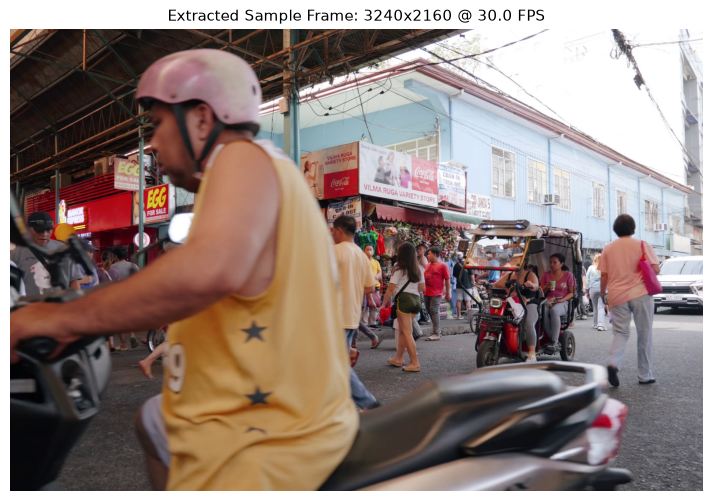

In [3]:
video_path = REPO_ROOT / "data" / "sample_videos" / "video_1.mp4"

cap = cv2.VideoCapture(str(video_path))
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration_sec = total_frames / max(fps, 1)

ret, raw_frame = cap.read()
cap.release()

print(f"[x] Video Stream: {video_path.name}")
print(f"    Resolution: {width}x{height} | FPS: {fps:.1f} | Total Frames: {total_frames} (~{duration_sec:.1f}s)")

if ret:
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(raw_frame, cv2.COLOR_BGR2RGB))
    plt.title(f"Extracted Sample Frame: {width}x{height} @ {fps:.1f} FPS", fontsize=11)
    plt.axis("off")

## 4. Stage 1: Detection via `DetectorFactory`
We instantiate the primary YOLOv11 detector through `DetectorFactory`. The detector returns standardized `supervision.Detections` containing bounding boxes, confidences, and class IDs.

In [4]:
from vision_ml.detection.detector_factory import DetectorFactory

detector = DetectorFactory.from_config(config)
detections = detector.detect(raw_frame)

print(f"[x] Primary Detector Output:")
print(f"    Persons Detected: {len(detections)}")
print(f"    Confidence Scores: {np.round(detections.confidence, 3)}")
print("    Bounding Boxes (xyxy, first 3):\n", np.round(detections.xyxy[:3], 1))

2026-11-11 16:30:43 | INFO     | vision_ml.detection.yolo_detector | Loading model weights from: D:\01_WORK\Career\Portfolio Projects\vision-ml-system\models\original\yolo11n.pt (FP16 on cuda:0)
[x] Primary Detector Output:
    Persons Detected: 8
    Confidence Scores: [      0.925       0.857       0.751       0.705       0.632       0.582       0.431       0.402]
    Bounding Boxes (xyxy, first 3):
 [[          0        92.3      1655.4        2136]
 [     2748.9         865      3052.7        1682]
 [       1744       984.5      1936.4        1601]]


## 5. Stage 2: Multi-Object Tracking via ByteTrack
Isolated detections lack temporal identity. We initialize `ByteTrack` via `TrackerFactory` to associate bounding boxes across consecutive frames and assign persistent track IDs.

In [5]:
from vision_ml.tracking.tracker_factory import TrackerFactory

tracker = TrackerFactory.from_config(config)
tracked_detections = tracker.update(detections)

print(f"[x] Tracker State Initialized:")
print(f"    Active Tracker IDs: {tracked_detections.tracker_id}")

[x] Tracker State Initialized:
    Active Tracker IDs: [-1 -1 -1 -1 -1 -1 -1 -1]


## 6. Stage 3: Superimposition & Visualization
Using `FrameAnnotator` (powered by Roboflow Supervision), we render colored bounding boxes and persistent visitor ID badges.

2026-11-11 16:30:48 | INFO     | vision_ml.annotation.annotator | Using BoxAnnotator (legacy)


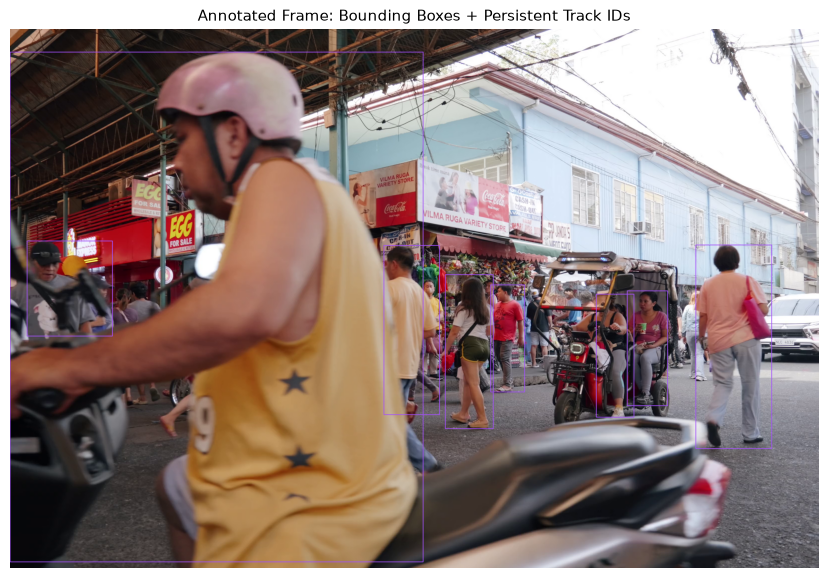

In [6]:
from vision_ml.annotation.annotator import FrameAnnotator

annotator = FrameAnnotator(config)
annotated_frame = annotator.annotate(raw_frame.copy(), tracked_detections)

plt.figure(figsize=(11, 7))
plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
plt.title(f"Annotated Frame: Bounding Boxes + Persistent Track IDs", fontsize=11)
plt.axis("off")

## 7. Stage 4: Real-Time Visitor Analytics & Dwell Time
We process 45 consecutive frames to observe `VisitorAnalytics` accumulating dwell time per tracked ID and computing occupancy.

In [7]:
from vision_ml.analytics.visitor_analytics import VisitorAnalytics

analytics = VisitorAnalytics(config)
cap = cv2.VideoCapture(str(video_path))

frame_idx = 0
while cap.isOpened() and frame_idx < 45:
    ret, frame = cap.read()
    if not ret:
        break
    
    dets = detector.detect(frame)
    dets = tracker.update(dets)
    
    tids = dets.tracker_id if dets.tracker_id is not None else []
    analytics.update(tids, frame_idx=frame_idx)
    frame_idx += 1

cap.release()

summary = analytics.get_summary()
print("================ Visitor Analytics Summary ================")
print(f"Unique Visitors Seen:   {summary.get('unique_visitors')}")
print(f"Total Processed Frames: {summary.get('total_frames')}")
print(f"Average Dwell Time (s): {summary.get('avg_dwell_time_seconds', 0.0):.2f}s")
print("\nVisitor Dwell Breakdown:")
for vid, stats in list(analytics.get_dwell_times().items())[:6]:
    print(f"  * Visitor #{vid}: {stats['duration_seconds']:.2f}s ({stats['duration_frames']} frames)")

================ Visitor Analytics Summary ================
Unique Visitors Seen:   17
Total Processed Frames: 45
Average Dwell Time (s): 0.93s

Visitor Dwell Breakdown:
  * Visitor #0: 1.50s (45 frames)
  * Visitor #1: 1.50s (45 frames)
  * Visitor #2: 1.03s (31 frames)
  * Visitor #3: 1.50s (45 frames)
  * Visitor #4: 0.53s (16 frames)
  * Visitor #-1: 1.23s (37 frames)


## 8. Stage 5: Local Edge Persistence (`data/analytics.db`)
In accordance with our **Privacy-First Architecture**, all customer telemetry is saved locally on the edge device in SQLite without transmitting video streams to third parties.

In [8]:
import sqlite3
import pandas as pd

db_path = REPO_ROOT / "data" / "analytics.db"
if db_path.exists():
    conn = sqlite3.connect(str(db_path))
    runs_df = pd.read_sql_query("SELECT run_id, total_frames, unique_visitors, avg_dwell_time_seconds, timestamp, status FROM inference_runs ORDER BY timestamp DESC LIMIT 5", conn)
    print("--- Recent Inference Runs in SQLite (data/analytics.db) ---")
    print(runs_df.to_string(index=False))
    conn.close()
else:
    print("[!] SQLite database not found.")

--- Recent Inference Runs in SQLite (data/analytics.db) ---
             run_id  total_frames  unique_visitors  avg_dwell_time_seconds           timestamp    status
run_20261111_132735          1536               23                    3.14 2026-11-11 07:57:35 completed
run_20261111_132543           882               56                    2.17 2026-11-11 07:55:43 completed
run_20261111_132309           360               73                    1.66 2026-11-11 07:53:09 completed


## 9. Stage 6: The Active Learning Hand-Off
How do we turn borderline inference uncertainty into training data? When YOLO detects targets with confidence in the ambiguous range (`0.15 <= conf < 0.50`), the frame is flagged for capture.

In [9]:
borderline_threshold = config.get("active_learning", {}).get("confidence_threshold", 0.50)
min_threshold = 0.15

borderline_count = 0
for conf in detections.confidence:
    if min_threshold <= conf < borderline_threshold:
        borderline_count += 1

print(f"[Active Learning Triage Logic]")
print(f"  * High-Confidence Threshold: >= {borderline_threshold} (Direct to Analytics)")
print(f"  * Hard-Case Harvest Range:   {min_threshold} <= conf < {borderline_threshold} (Capture for Flywheel)")
print(f"  * Low-confidence candidates flagged: {borderline_count}")
print(f"-> In Notebook 02, we examine how these captured frames are automatically pseudo-labeled by the RF-DETR teacher transformer.")

[Active Learning Triage Logic]
  * High-Confidence Threshold: >= 0.5 (Direct to Analytics)
  * Hard-Case Harvest Range:   0.15 <= conf < 0.5 (Capture for Flywheel)
  * Low-confidence candidates flagged: 2
-> In Notebook 02, we examine how these captured frames are automatically pseudo-labeled by the RF-DETR teacher transformer.


---
### Key Takeaways from Notebook 01:
1. **Decoupled Architecture:** `DetectorFactory` and `TrackerFactory` allow hot-swapping models without modifying pipeline logic.
2. **Real-Time Performance:** YOLOv11 FP16 runs at ~4.2 ms on the RTX 4050, leaving plenty of compute headroom for ByteTrack and analytics.
3. **Local-First Privacy:** Zero video pixels leave the premises; only aggregate counts and dwell times are stored in SQLite.
4. **Autonomous Hand-Off:** Ambiguous frames are captured directly to `data/low_confidence_frames/` to feed the active learning loop.

Proceed to **`02_active_learning_flywheel.ipynb`** to inspect the Teacher-Student recovery mechanism.